# NYC Airbnb Room Type Classification

**Dataset:** [New York City Airbnb Open Data](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data) (Kaggle)

**Goal:** Predict the `room_type` of an Airbnb listing (`Entire home/apt`, `Private room`, or `Shared room`) using listing attributes such as price, location, availability, and review activity.

# 1. Import Library

In [233]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# 2. Import the Dataset

In [234]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, "AB_NYC_2019.csv"))
df.head()

Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.
Path to dataset files: /kaggle/input/new-york-city-airbnb-open-data


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


# 3. Inspect The Dataset

In [235]:
df.shape

(48895, 16)

In [236]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [237]:
df.duplicated().sum()

np.int64(0)

In [238]:
df['id'].duplicated().sum()

np.int64(0)

In [239]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [240]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,48895.0,1.901714e+07,1.098311e+07,2539.00000,9.471945e+06,1.967728e+07,2.915218e+07,3.648724e+07
host_id,48895.0,6.762001e+07,7.861097e+07,2438.00000,7.822033e+06,3.079382e+07,1.074344e+08,2.743213e+08
latitude,48895.0,4.072895e+01,5.453008e-02,40.49979,4.069010e+01,4.072307e+01,4.076311e+01,4.091306e+01
longitude,48895.0,-7.395217e+01,4.615674e-02,-74.24442,-7.398307e+01,-7.395568e+01,-7.393627e+01,-7.371299e+01
price,48895.0,1.527207e+02,2.401542e+02,0.00000,6.900000e+01,1.060000e+02,1.750000e+02,1.000000e+04
minimum_nights,48895.0,7.029962e+00,2.051055e+01,1.00000,1.000000e+00,3.000000e+00,5.000000e+00,1.250000e+03
number_of_reviews,48895.0,2.327447e+01,4.455058e+01,0.00000,1.000000e+00,5.000000e+00,2.400000e+01,6.290000e+02
reviews_per_month,38843.0,1.373221e+00,1.680442e+00,0.01000,1.900000e-01,7.200000e-01,2.020000e+00,5.850000e+01
calculated_host_listings_count,48895.0,7.143982e+00,3.295252e+01,1.00000,1.000000e+00,1.000000e+00,2.000000e+00,3.270000e+02
availability_365,48895.0,1.127813e+02,1.316223e+02,0.00000,0.000000e+00,4.500000e+01,2.270000e+02,3.650000e+02


# 4. EDA

In [241]:
df.describe(include='object').T

,count,unique,top,freq
name,48879,47905,Hillside Hotel,18
host_name,48874,11452,Michael,417
neighbourhood_group,48895,5,Manhattan,21661
neighbourhood,48895,221,Williamsburg,3920
room_type,48895,3,Entire home/apt,25409
last_review,38843,1764,2019-06-23,1413


## 4.1 Missing Value

In [242]:
missing = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_df = pd.DataFrame({
    'Missing_Count': missing,
    'Missing_Percentage': missing_percentage
})

missing_df[missing_df['Missing_Count'] > 0].sort_values('Missing_Percentage', ascending=False)

,Missing_Count,Missing_Percentage
last_review,10052,20.558339
reviews_per_month,10052,20.558339
host_name,21,0.042949
name,16,0.032723


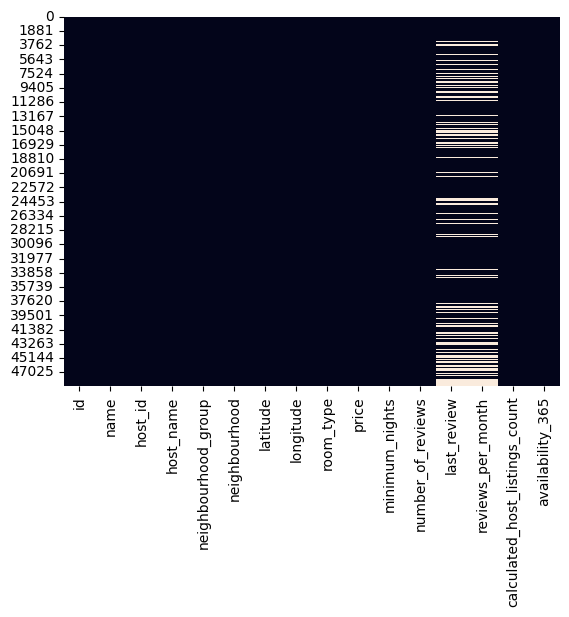

In [243]:
sns.heatmap(df.isnull(), cbar=False)
plt.show()

## 4.2 Target Variable - room_type

In [244]:
df['room_type'].value_counts(normalize=True) * 100

,proportion
room_type,
Entire home/apt,51.966459
Private room,45.661111
Shared room,2.372431


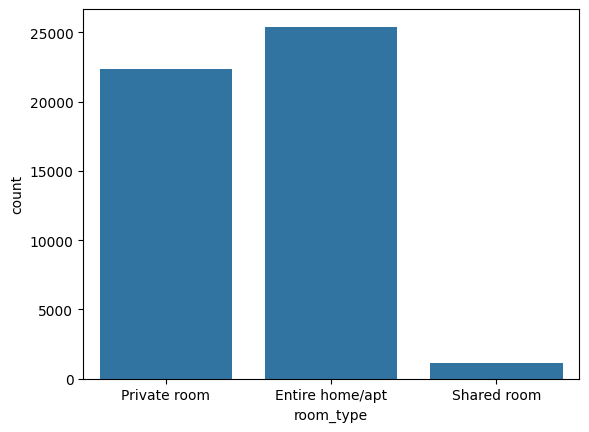

In [245]:
sns.countplot(x=df['room_type'])
plt.show()

### The classes are imbalanced -> shared room is a minority

## 4.3 Univariate Analysis - Num

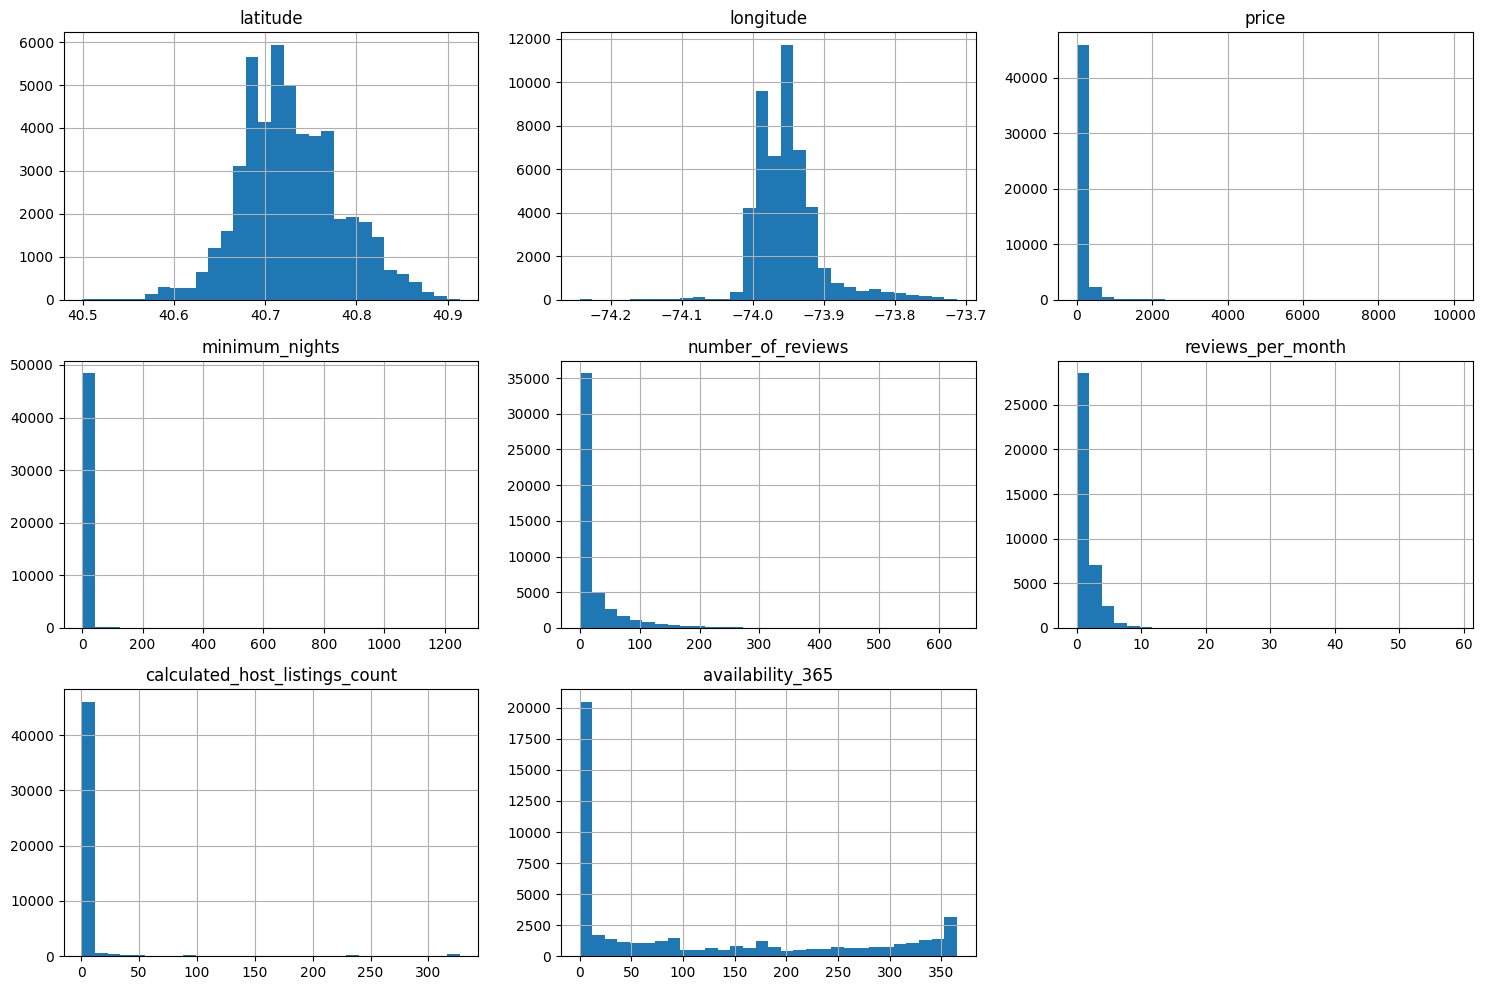

In [246]:
numerical_cols = [
    'latitude',
    'longitude',
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365'
]

df[numerical_cols].hist(
    figsize=(15, 10),
    bins=30
)

plt.tight_layout()
plt.show()

In [247]:
df[numerical_cols].skew()

,0
latitude,0.237167
longitude,1.284210
price,19.118939
minimum_nights,21.827275
number_of_reviews,3.690635
reviews_per_month,3.130189
calculated_host_listings_count,7.933174
availability_365,0.763408


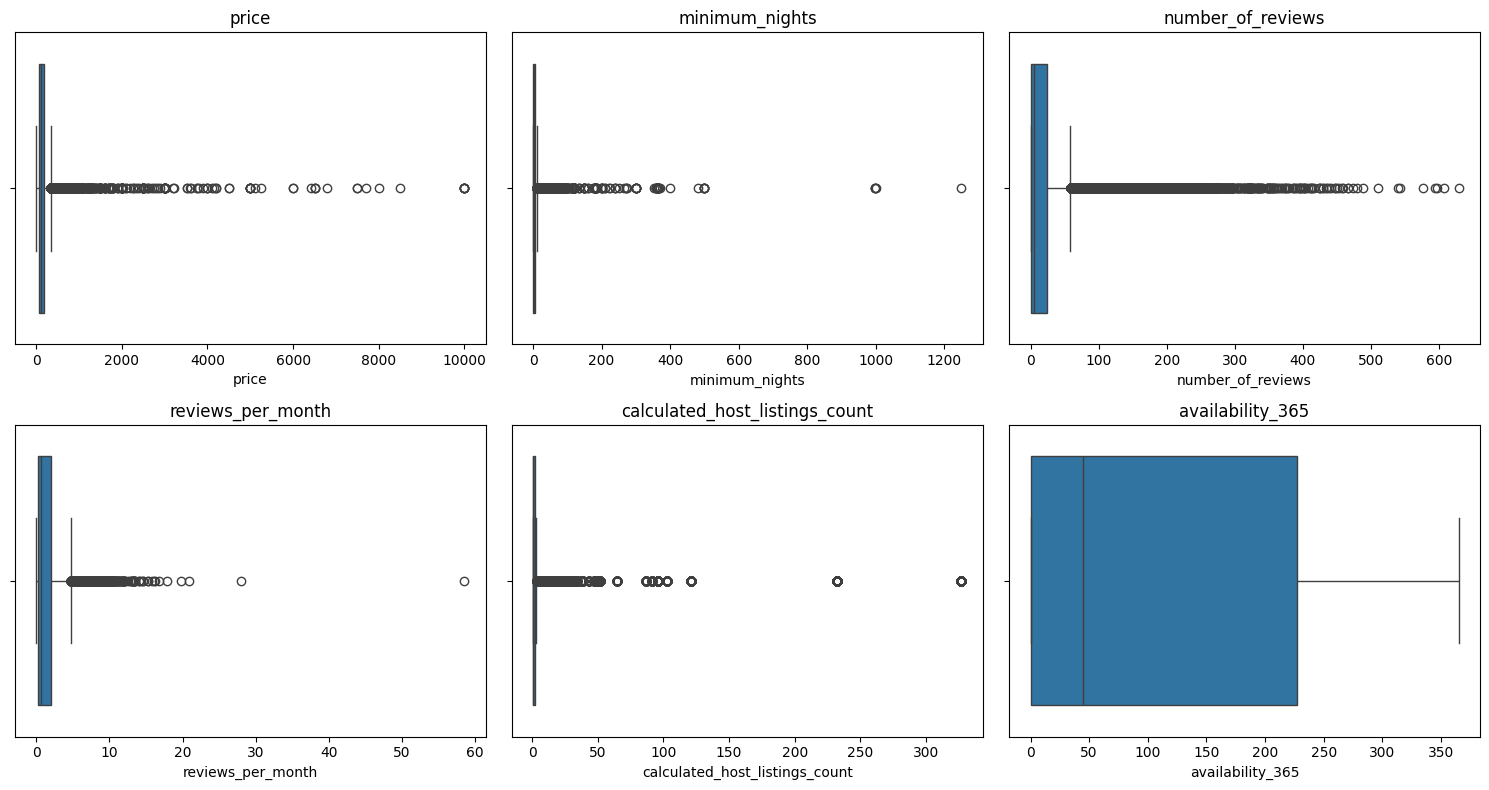

In [248]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

cols = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365'
]

for ax, col in zip(axes.flat, cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## 4.4 Univariate Analysis - Cat

In [249]:
categorical_cols = [
    'neighbourhood_group',
    'room_type'
]

for col in categorical_cols:
    print(f'\n{col}')
    print(df[col].value_counts())


neighbourhood_group
neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64

room_type
room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64


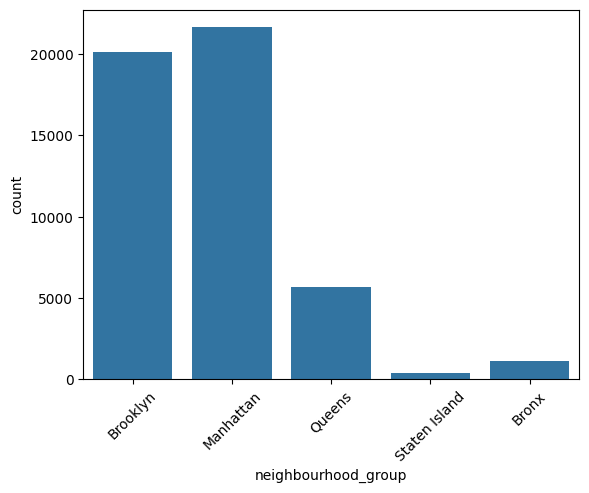

In [250]:
sns.countplot(data=df, x='neighbourhood_group')
plt.xticks(rotation=45)
plt.show()

### Queens, Staten Island, Bronx -> Are Minority class

## 4.5 Bivariate Analysis - Features vs Target

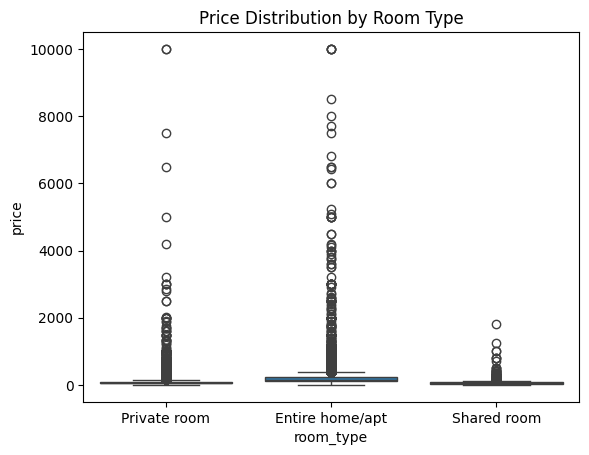

In [251]:
sns.boxplot(
    data=df,
    x='room_type',
    y='price'
)

plt.title('Price Distribution by Room Type')
plt.show()

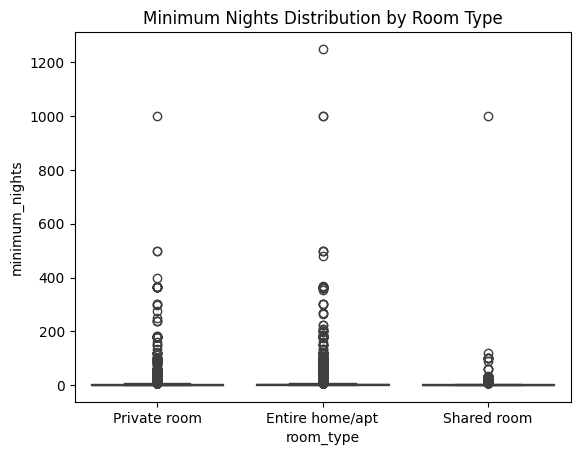

In [252]:
sns.boxplot(
    data=df,
    x='room_type',
    y='minimum_nights'
)

plt.title('Minimum Nights Distribution by Room Type')
plt.show()

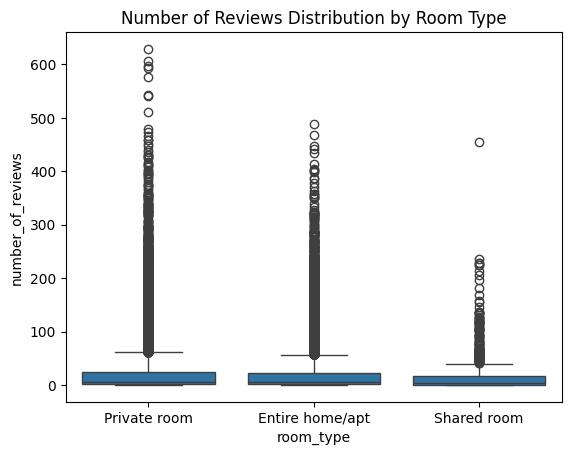

In [253]:
sns.boxplot(
    data=df,
    x='room_type',
    y='number_of_reviews'
)

plt.title('Number of Reviews Distribution by Room Type')
plt.show()

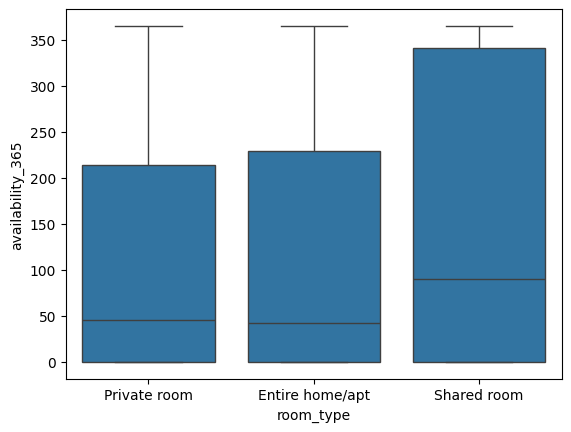

In [254]:
sns.boxplot(
    data=df,
    x='room_type',
    y='availability_365'
)

plt.show()

In [255]:
pd.crosstab(
    df['neighbourhood_group'],
    df['room_type'],
    normalize='index'
)

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,0.347388,0.597617,0.054995
Brooklyn,0.475478,0.503979,0.020543
Manhattan,0.609344,0.368496,0.022160
Queens,0.369926,0.595129,0.034945
Staten Island,0.471850,0.504021,0.024129


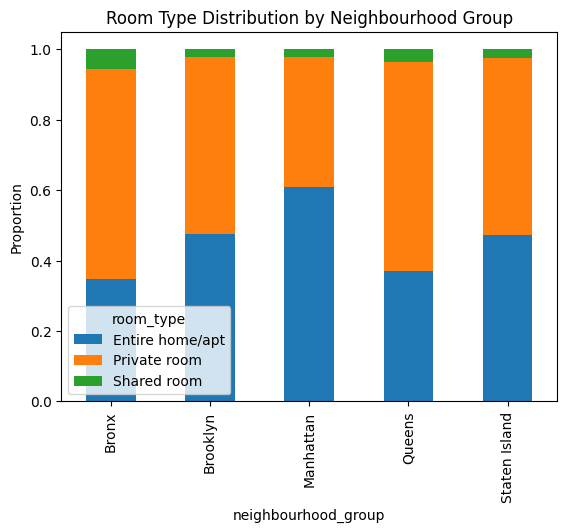

In [256]:
pd.crosstab(
    df['neighbourhood_group'],
    df['room_type'],
    normalize='index'
).plot(kind='bar', stacked=True)

plt.ylabel('Proportion')
plt.title('Room Type Distribution by Neighbourhood Group')
plt.show()

In [257]:
top_neighbourhoods = (
    df['neighbourhood']
    .value_counts()
    .head(10)
    .index
)

temp = df[df['neighbourhood'].isin(top_neighbourhoods)]

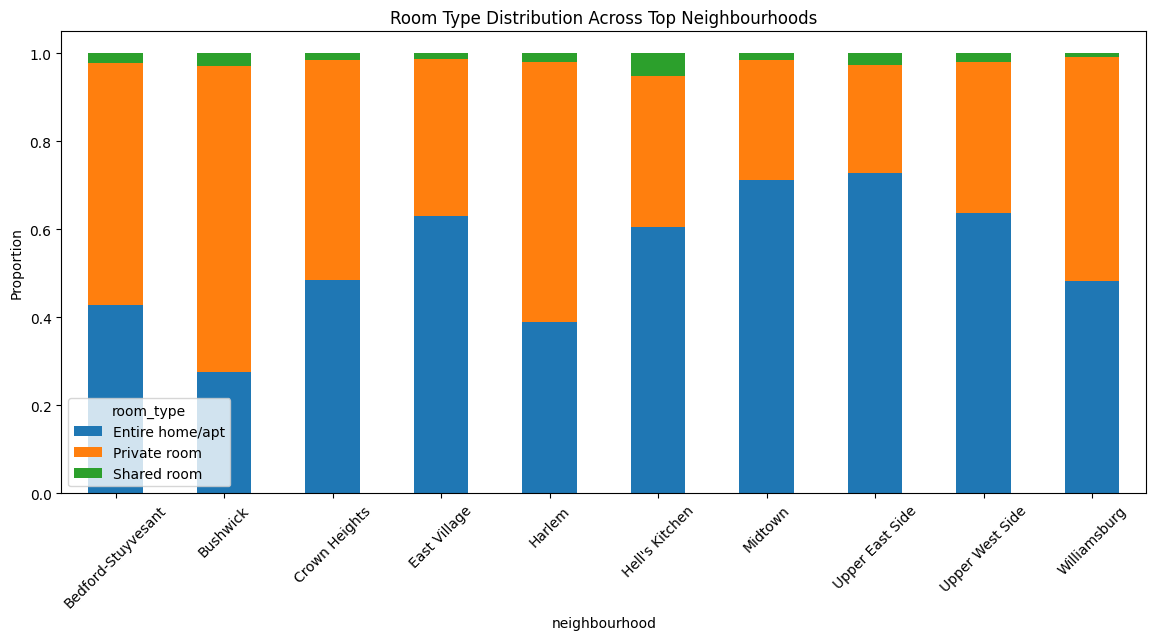

In [258]:
pd.crosstab(
    temp['neighbourhood'],
    temp['room_type'],
    normalize='index'
).plot(
    kind='bar',
    stacked=True,
    figsize=(14, 6)
)

plt.ylabel('Proportion')
plt.title('Room Type Distribution Across Top Neighbourhoods')
plt.xticks(rotation=45)
plt.show()

## 4.6 Correlation Between Numeric Features

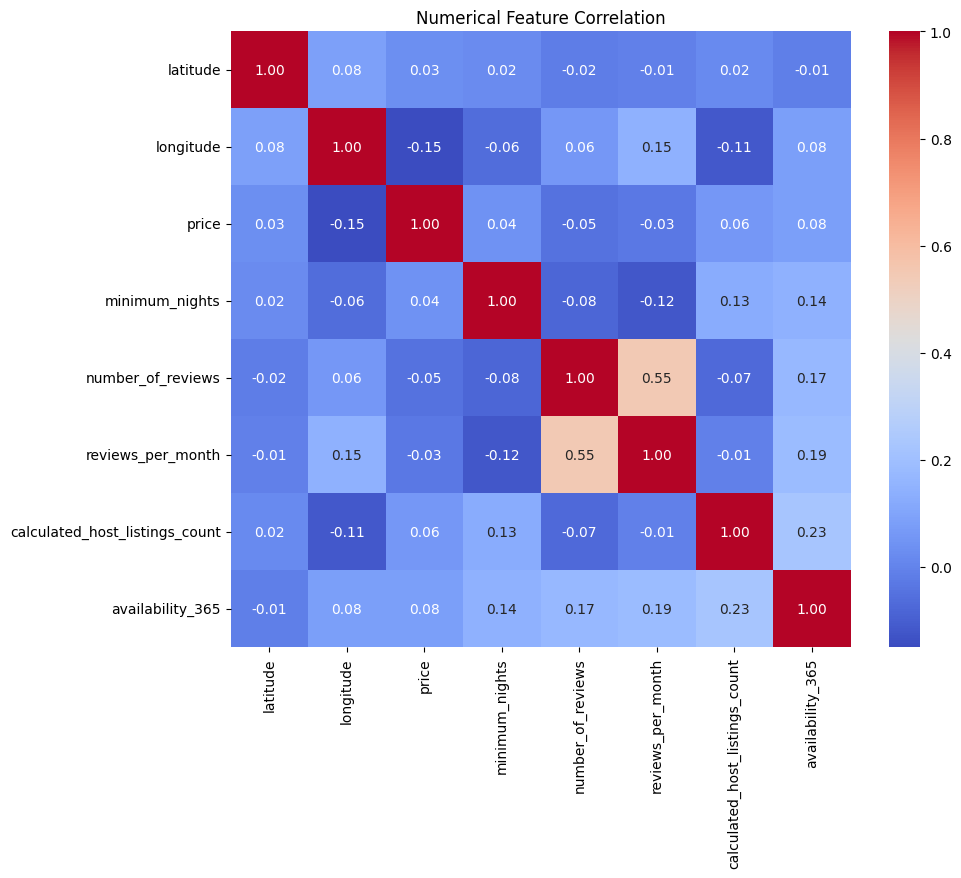

In [259]:
corr = df[numerical_cols].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Numerical Feature Correlation')
plt.show()

## 4.7 Geogarphic Distribution

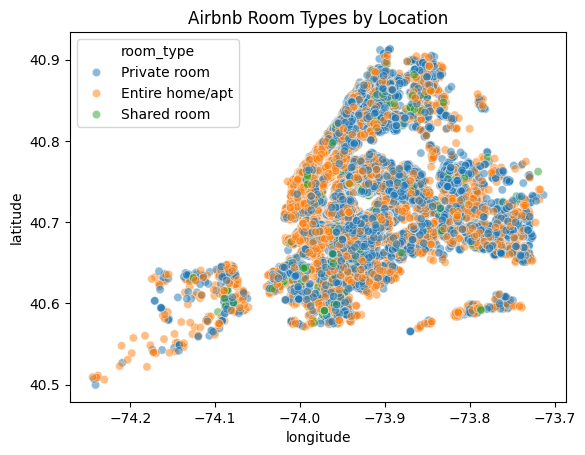

In [260]:
sns.scatterplot(
    data=df,
    x='longitude',
    y='latitude',
    hue='room_type',
    alpha=0.5
)

plt.title('Airbnb Room Types by Location')
plt.show()

In [261]:
df[numerical_cols + ['room_type']].groupby('room_type').mean()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
room_type,,,,,,,,
Entire home/apt,40.728649,-73.960696,211.794246,8.506907,22.842418,1.306578,10.698335,111.920304
Private room,40.729208,-73.942924,89.780973,5.377900,24.112962,1.445209,3.227717,111.203933
Shared room,40.730514,-73.943343,70.127586,6.475000,16.600000,1.471726,4.662931,162.000862


# 5. Data Cleaning and Feature Engineering

In [262]:
# Drop the columns which are not usefull to predict the traget variable
df_clean = df.drop(columns=['id', 'name', 'host_id', 'host_name', 'last_review'])

In [263]:
df_clean.isnull().sum()

,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0
minimum_nights,0
number_of_reviews,0
reviews_per_month,10052
calculated_host_listings_count,0


In [ ]:

df_clean['number_of_reviews'] = df_clean['number_of_reviews'].fillna(0)

In [265]:
cat_cols = df_clean.select_dtypes(include='object').columns.to_list()

In [266]:
for col in cat_cols:
  print(df[col].value_counts())
  print()

neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64

neighbourhood
Williamsburg          3920
Bedford-Stuyvesant    3714
Harlem                2658
Bushwick              2465
Upper West Side       1971
                      ... 
Richmondtown             1
Fort Wadsworth           1
New Dorp                 1
Rossville                1
Willowbrook              1
Name: count, Length: 221, dtype: int64

room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64



# 6. Train-Test Split

In [267]:
from sklearn.model_selection import train_test_split

X = df_clean.drop('room_type', axis=1)
y = df_clean['room_type']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [268]:
clip_cols = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count'
]

caps = {}

for col in clip_cols:
    caps[col] = X_train[col].quantile(0.99)

    X_train[col] = X_train[col].clip(upper=caps[col])
    X_test[col] = X_test[col].clip(upper=caps[col])

In [269]:
clip_values = pd.DataFrame(
    caps.items(),
    columns=['Feature', '99th_Percentile_Cap']
)

clip_values

,Feature,99th_Percentile_Cap
0,price,799.0000
1,minimum_nights,45.0000
2,number_of_reviews,214.0000
3,reviews_per_month,7.2107
4,calculated_host_listings_count,232.0000


# 7. Preprocessing: ColumnTransformer + Pipeline

In [284]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer

In [285]:
log_transformer = FunctionTransformer(
    np.log1p,
    feature_names_out="one-to-one"
)



log_features = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count"
]

other_numerical_features = [
    "latitude",
    "longitude",
    "availability_365"
]

categorical_features = ['neighbourhood_group', 'neighbourhood']

In [288]:
log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )),
    ("scaler", StandardScaler())
])

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])


preprocessor = ColumnTransformer([
    ("log_numeric", log_pipeline, log_features),
    ("numeric", numerical_pipeline, other_numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [289]:
preprocessor

ColumnTransformer(transformers=[('log_numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scaler', StandardScaler())]),
                                 ['price', 'minimum_nights',
                                  'number_of_reviews', 'reviews_per_month',
                                  'calculated_host_listings_count']),
                                ('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['latitude', 'longitude', 'availability_365']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                min_frequency=10))]),
                                 ['neighbourhood_group', 'neighbourhood'])])

# 8. Trying Multiple Algorithms

# To solve the Imbalance class:-

## A. SMOTE (Synthetic Minority Oversampling) for class IMbalance
---
1. High chances of Overfitting.
2. Data Leakage


## B. class_weight="Balanced"
- tells the model to pay more attention to the minority class or rare class
---
1. But the problem is GradintBossting doesnt support class weight so we left it as it is.

In [290]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

In [293]:
models = {
'Logistic Regression': LogisticRegression(class_weight='balanced', random_state=42, max_iter=500),
'K-Nearest Neighbors': KNeighborsClassifier(),
'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

In [292]:
from sklearn.model_selection import cross_validate

results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            'accuracy': 'accuracy',
            'macro_f1': 'f1_macro'
        }
    )

    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Macro F1': scores['test_macro_f1'].mean()
    })

results_df = pd.DataFrame(results)

results_df[['Accuracy', 'Macro F1']] = results_df[
    ['Accuracy', 'Macro F1']
].round(3)



,Model,Accuracy,Macro F1
3,Random Forest,0.855,0.723
4,Gradient Boosting,0.851,0.703
1,K-Nearest Neighbors,0.818,0.688
2,Decision Tree,0.789,0.661
0,Logistic Regression,0.719,0.570


In [294]:
results_df.sort_values(by='Macro F1', ascending=False).reset_index(drop=True)

,Model,Accuracy,Macro F1
0,Random Forest,0.855,0.723
1,Gradient Boosting,0.851,0.703
2,K-Nearest Neighbors,0.818,0.688
3,Decision Tree,0.789,0.661
4,Logistic Regression,0.719,0.570


## I Choose the RandomForest Model

# 9. Hyperparameter Tuning

In [296]:
from sklearn.model_selection import RandomizedSearchCV
best_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))
])

param_distributions = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [8, 12, 15, 20, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
}


search = RandomizedSearchCV(
    estimator=best_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    cv=3,
    scoring='f1_macro',
    random_state=42,
    verbose=1,
    n_jobs=-1
)

search.fit(X_train, y_train)


Fitting 3 folds for each of 10 candidates, totalling 30 fits


RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('log_numeric',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('log',
                                                                                                FunctionTransformer(feature_names_out='one-to-one',
                                                                                                                    func=<ufunc 'log1p'>)),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['price',
                                                                                'minimum_nights',
                                                                                'number_of_reviews',
                                                                                'reviews_per_month',...
                                                                               ['neighbourhood_group',
                                                                                'neighbourhood'])])),
                                             ('classifier',
                                              RandomForestClassifier(class_weight='balanced',
                                                                     random_state=42))]),
                   n_jobs=-1,
                   param_distributions={'classifier__max_depth': [8, 12, 15, 20,
                                                                  None],
                                        'classifier__min_samples_leaf': [1, 2,
                                                                         4],
                                        'classifier__min_samples_split': [2, 5,
                                                                          10],
                                        'classifier__n_estimators': [100, 200,
                                                                     300]},
                   random_state=42, scoring='f1_macro', verbose=1)

In [297]:
print(f"Best F1 Score: {search.best_score_}")
print(f"Best Parameters: {search.best_params_}")

Best F1 Score: 0.733802579556072
Best Parameters: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': None}


# 10. Final Evaluation on the Test Set

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

best_model = search.best_estimator_

y_pred = best_model.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred)}")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")}")

Accuracy Score: 0.8541141182084668
F1 Score: 0.758245080723522


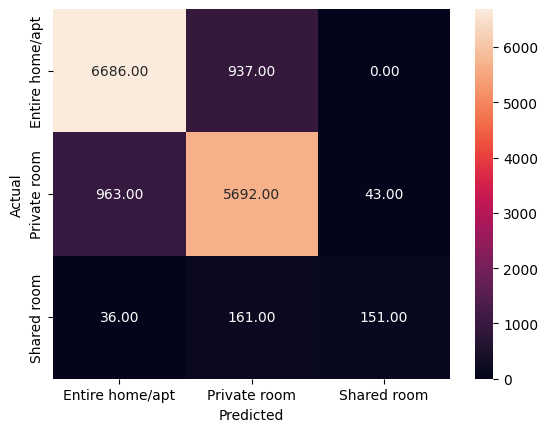

In [304]:
sns.heatmap(confusion_matrix(y_test,y_pred), annot=True, fmt=".2f", xticklabels=np.unique(y_test), yticklabels=np.unique(y_test))
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# 11. Saving the Final Model Artifact

In [305]:
import joblib

joblib.dump(best_model, 'airbnb_model.pkl')

['airbnb_model.pkl']

In [306]:
df_clean.columns

Index(['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')